In [1]:
# conda vis2
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent

import sys
sys.path.append(str(PROJECT_ROOT))

import numpy as np
import at3d
import matplotlib.pyplot as plt
import xarray as xr
from src.utils.util import load_sensor_dict, load_config, set_labels
from scipy.interpolate import griddata

In [2]:
def interp_sensor_to_rte_grid(sensor, rte_grid, interp_var_name):
    x_sensor = sensor.ray_x.data
    y_sensor = sensor.ray_y.data
    interp_var = sensor[interp_var_name].data

    x_interp_to = rte_grid.x.data
    y_interp_to = rte_grid.y.data

    grid_x, grid_y = np.meshgrid(x_interp_to, y_interp_to, indexing='ij')
    var_interpolated = griddata((x_sensor, y_sensor), interp_var, (grid_x, grid_y), method='linear')
    rte_grid[interp_var_name] = (['x', 'y'], var_interpolated)
    return rte_grid

In [3]:
savefigs = True

EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
ITERATIONS = EXPERIMENT / 'iterations'
TAU_1D = EXPERIMENT / 'tau_1D'
FIGURE_OUT = EXPERIMENT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

config = load_config(EXPERIMENT / 'config.yml')

In [4]:
iter_files = sorted(ITERATIONS.glob('iter*.nc'))
iter_file = iter_files[-1]

sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_file)
at3d_cloud = solvers[0.67].medium['cloud']
at3d_cloud['tau'] = at3d_cloud.extinction.integrate('z')
nan_at3d_tau = at3d_cloud.tau.copy(deep=True).data
nan_at3d_tau[nan_at3d_tau == 0] = np.nan
at3d_cloud['tau'] = (['x', 'y'], nan_at3d_tau)

cvm = xr.load_dataset(config['cloud_volume_mask_file'])

tau1D_file = TAU_1D / 'TAU_1D_{}.nc'.format(config['obs_file'].stem)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '71'. Max cell optical depth: '3.4591331481933594'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


1D is 20.57% lower than AT3D


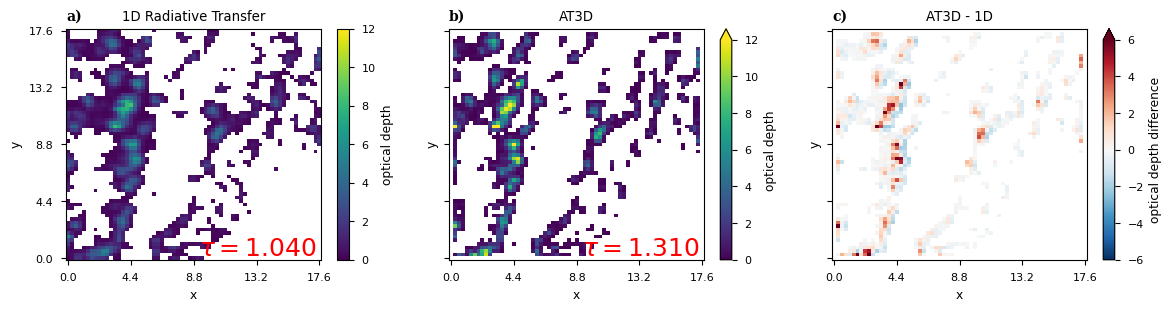

In [5]:
# Load the 1D Tau retreival
obs = load_sensor_dict(tau1D_file)
tau_1D_sensor = obs['MISR']['sensor_list'][4]

# Interpolate to same grid
cloud_1D = rte_grid.copy(deep=True)
cloud_1D.attrs = tau_1D_sensor.attrs
cloud_1D = interp_sensor_to_rte_grid(tau_1D_sensor, cloud_1D, 'tau')
cloud_1D = interp_sensor_to_rte_grid(tau_1D_sensor, cloud_1D, 'I')

# Derive cloud masks
cvm['cloud_mask_cvm'] = (cvm.cloud_volume_mask.integrate('z') > 0).astype(int)
cvm['cloud_mask_at3d'] = (at3d_cloud.tau > 0).astype(int)
th_mask = (((np.pi * cloud_1D.I) / cloud_1D.mu0) > 0.04).astype(int).data
th_mask[0,:] = th_mask[-1,:] = th_mask[:,0] = th_mask[:,-1] = 0
cvm['cloud_mask_th'] = (['x', 'y'], th_mask)
cvm['cloud_mask_1D_not_nan'] = np.logical_not(np.isnan(cloud_1D.tau)).astype(int)

# Set visuialization parameters
vmin = 0
vmax = 12
vrange = 6
# cloud_mask_name = 'cloud_mask_cvm'
# cloud_mask_name = 'cloud_mask_at3d'
# cloud_mask_name = 'cloud_mask_th'
# cloud_mask_name = 'cloud_mask_1D_not_nan'
cloud_mask_name = 'cloud_mask_none'

# Plot
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharex=True, sharey=True)
# Plot Tau
cloud_1D.tau.plot(
    ax=ax[0],
    y='y',
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={'label': 'optical depth'}
)
at3d_cloud.tau.plot(
    ax=ax[1],
    y='y',
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={'label': 'optical depth'}
)
(at3d_cloud.tau - cloud_1D.tau).plot(
    ax=ax[2],
    y='y',
    vmin=-vrange,
    vmax=vrange,
    cbar_kwargs={'label': 'optical depth difference'},
    cmap='RdBu_r'
)
# Plot cloud mask contours
# cm_colors = ['r', 'r', 'r']
# ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
# for i in range(len(ax)):
#     cvm[cloud_mask_name].plot.contour(
#         y='y',
#         levels=1,
#         ax=ax[i],
#         colors=cm_colors[i],
#         linewidths=0.5
#     )
#     ax[i].set_xlabel('x (km)')
#     ax[i].set_ylabel('y (km)')
#     ax[i].set_xticks(ticks)
#     ax[i].set_yticks(ticks)
ax[0].set_title('1D Radiative Transfer')
ax[1].set_title('AT3D')
ax[2].set_title('AT3D - 1D')

# Calculate Tau averages over cloud mask
# tau_bar_1d = cloud_1D.tau.where(cvm[cloud_mask_name] > 0).mean().data
# tau_bar_3d = at3d_cloud.tau.where(cvm[cloud_mask_name] > 0).mean().data
tau_bar_1d = cloud_1D.tau.mean().data
tau_bar_3d = at3d_cloud.tau.mean().data

# Print Tau average
ax[0].text(17.4, 0.2, r'$\tau = {:.3f}$'.format(tau_bar_1d), ha='right', c='r', size=18)
ax[1].text(17.4, 0.2, r'$\tau = {:.3f}$'.format(tau_bar_3d), ha='right', c='r', size=18)

# Calculate difference 1D vs AT3D
# print('Cloud mask: {}'.format(cloud_mask_name))
print('1D is {:.2f}% lower than AT3D'.format(100*(tau_bar_3d - tau_bar_1d) / tau_bar_3d))

# Adjust ticks
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
for a in ax.flat:
    a.set_xticks(ticks)
    a.set_xticklabels(ticks)
    a.set_yticks(ticks)
set_labels(ax.flatten())

# Save figure
if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'optical_depth_{}_{}.png'.format(cloud_mask_name, iter_file.stem),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )


In [6]:

rel_diff = 100 * (np.sum((cloud_1D.tau - at3d_cloud.tau)**2))**0.5 / (np.sum(at3d_cloud.tau)**2)**0.5
rel_bias = 100 * (np.sum(np.abs(cloud_1D.tau)) - np.sum(np.abs(at3d_cloud.tau))) / (np.sum(np.abs(at3d_cloud.tau)))
print('Relative Difference: {:.2f}'.format(rel_diff.data))
print('Relative Bias: {:.2f}'.format(rel_bias.data))


Relative Difference: 2.46
Relative Bias: -0.42
